## Comparing tracks on the globe to Preistly NH

In this file I compare the raw tracks from Priestly to the filtered tracks.
The goal is to verify that the postprocessing method keeps the correct tracks.

# Workflow
1. Load raw priestly tracks and own raw tracks 
2. Clip all tracks to domain and update the track-ids
3. Convert both datasets to TRACK objects
4. Run postprocessing algorithm objects
5. validate by comparing the filtered objects of both sets
6. As fraction of overlap is 1.0 and mean_sep_km is 0.0 i can conclude that the tracks are identical. 
7. This means that my postprocessing filter keeps the same tracks as Preistly in the chosen domain when used on raw tracks

In [188]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs
import pystormtracker as pst

import sys
import os

module_dir = (Path.cwd() / ".." /".."/ "algorithms"/"track_style_alg").resolve()
sys.path.insert(0,str(module_dir))


print("cwd:", Path.cwd())
print("module_dir:", module_dir)
print("exists:", module_dir.exists())
print("contents:", sorted(p.name for p in module_dir.iterdir()) if module_dir.exists() else None)

import validation as val
import processing as pro
import helpers
from configs import *




import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel




cwd: /Users/asgerthormann/Documents/uni/master/master_code/master_thesis/experiments/validation_tracks
module_dir: /Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg
exists: True
contents: ['__pycache__', 'configs.py', 'helpers.py', 'processing.py', 'validation.py']


<module 'processing' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg/processing.py'>

In [189]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
df_all = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_ALL_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_all=df_all.rename(columns={'vorticity': 'vo'})
print("Number of all tracks:", len(df_all['track_id'].unique()))

Number of all tracks: 2492


In [190]:
# df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
# df_validation=df_validation.rename(columns={'vorticity': 'vo'})
# print("Number of validation tracks:", len(df_validation['track_id'].unique()))

In [191]:
tracks_global = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_spectral_taper.trackjson')
tracks_global.metadata

TracksMetadata(primary_variable='vo', mode='max', units=mappingproxy({'vo': 's^-1', 'raw_value': 's^-1', 'object_gridcell_area_km2': 'km2', 'object_moment_fitted_area_km2': 'km2', 'object_moment_major_axis_km': 'km', 'object_moment_minor_axis_km': 'km', 'object_moment_orientation_degrees': 'degrees'}), bounds=SpatialBounds(south=20.0, north=90.0, west=-90.0, east=30.0), processing=(ProcessingStep(operation='spatial_taper', enabled=True, parameters=mappingproxy({'points': 10})), ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'dct', 'lmin': 5, 'lmax': 42, 'spectral_taper': 0.1}))))

In [192]:
df_global = helpers.tracks_to_points(tracks_global)
df_global

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo
0,2,1998-12-16 06:00:00,82.00,-45.75,4.136015e+06,6.093084e+06,1886.856294,1027.894278,-81.927738,0.000021,0.000021
1,2,1998-12-16 12:00:00,81.00,-37.25,4.445807e+06,7.366062e+06,2028.566664,1155.836001,-76.732084,0.000013,0.000013
2,2,1998-12-16 18:00:00,79.75,-3.25,9.724353e+05,9.646240e+05,1011.103154,303.677567,-72.438392,0.000035,0.000035
3,2,1998-12-17 00:00:00,80.50,16.00,5.224897e+06,6.855766e+06,2409.398488,905.727385,65.477976,0.000021,0.000021
4,2,1998-12-17 06:00:00,80.50,3.25,4.770863e+06,6.549630e+06,2564.549632,812.934872,68.140630,0.000056,0.000056
...,...,...,...,...,...,...,...,...,...,...,...
7309,1733,1999-02-24 00:00:00,75.50,-61.50,2.253217e+05,1.546171e+05,285.876399,172.158834,-85.245363,0.000030,0.000030
7310,1733,1999-02-24 06:00:00,75.00,-65.75,3.248548e+05,2.574018e+05,379.088316,216.133144,-63.809280,0.000032,0.000032
7311,1733,1999-02-24 12:00:00,74.50,-65.50,3.980854e+05,3.247737e+05,528.780368,195.504017,-62.228376,0.000039,0.000039
7312,1733,1999-02-24 18:00:00,74.75,-68.00,4.460291e+05,3.305694e+05,516.060943,203.897476,-63.417448,0.000029,0.000029


In [193]:
ratio = df_global["vo"] / df_global["raw_value"]
print(ratio.describe())   # median near 1.0 (up to ~1.05) rules the refinement out

count    7314.000000
mean        1.000824
std         0.051631
min         0.925225
25%         1.000000
50%         1.000000
75%         1.000000
max         4.710851
dtype: float64


In [194]:
df_global = val.clip_to_domain(df_global, DOMAIN, TIME_RANGE)
df_all = val.clip_to_domain(df_all, DOMAIN, TIME_RANGE)
print("Number of global tracks after clipping to domain:", len(df_global['track_id'].unique()))
print("Number of all tracks after clipping to domain:", len(df_all['track_id'].unique()))

Number of global tracks after clipping to domain: 868
Number of all tracks after clipping to domain: 602


In [195]:
ratio = df_global["vo"] / df_global["raw_value"]
print(ratio.describe())   # median near 1.0 (up to ~1.05) rules the refinement out

count    7314.000000
mean        1.000824
std         0.051631
min         0.925225
25%         1.000000
50%         1.000000
75%         1.000000
max         4.710851
dtype: float64


In [196]:
df_global

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo,segment
0,200,1998-12-16 06:00:00,82.00,-45.75,4.136015e+06,6.093084e+06,1886.856294,1027.894278,-81.927738,0.000021,0.000021,0
1,200,1998-12-16 12:00:00,81.00,-37.25,4.445807e+06,7.366062e+06,2028.566664,1155.836001,-76.732084,0.000013,0.000013,0
2,200,1998-12-16 18:00:00,79.75,-3.25,9.724353e+05,9.646240e+05,1011.103154,303.677567,-72.438392,0.000035,0.000035,0
3,200,1998-12-17 00:00:00,80.50,16.00,5.224897e+06,6.855766e+06,2409.398488,905.727385,65.477976,0.000021,0.000021,0
4,200,1998-12-17 06:00:00,80.50,3.25,4.770863e+06,6.549630e+06,2564.549632,812.934872,68.140630,0.000056,0.000056,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7309,173300,1999-02-24 00:00:00,75.50,-61.50,2.253217e+05,1.546171e+05,285.876399,172.158834,-85.245363,0.000030,0.000030,0
7310,173300,1999-02-24 06:00:00,75.00,-65.75,3.248548e+05,2.574018e+05,379.088316,216.133144,-63.809280,0.000032,0.000032,0
7311,173300,1999-02-24 12:00:00,74.50,-65.50,3.980854e+05,3.247737e+05,528.780368,195.504017,-62.228376,0.000039,0.000039,0
7312,173300,1999-02-24 18:00:00,74.75,-68.00,4.460291e+05,3.305694e+05,516.060943,203.897476,-63.417448,0.000029,0.000029,0


In [197]:
tracks_global = val.dataframe_to_tracks(df_global, variable = 'vo', scale=1)  # already in s^-1
tracks_all = val.dataframe_to_tracks(df_all, variable = 'vo', scale=1e-5)  # convert to s^-1

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


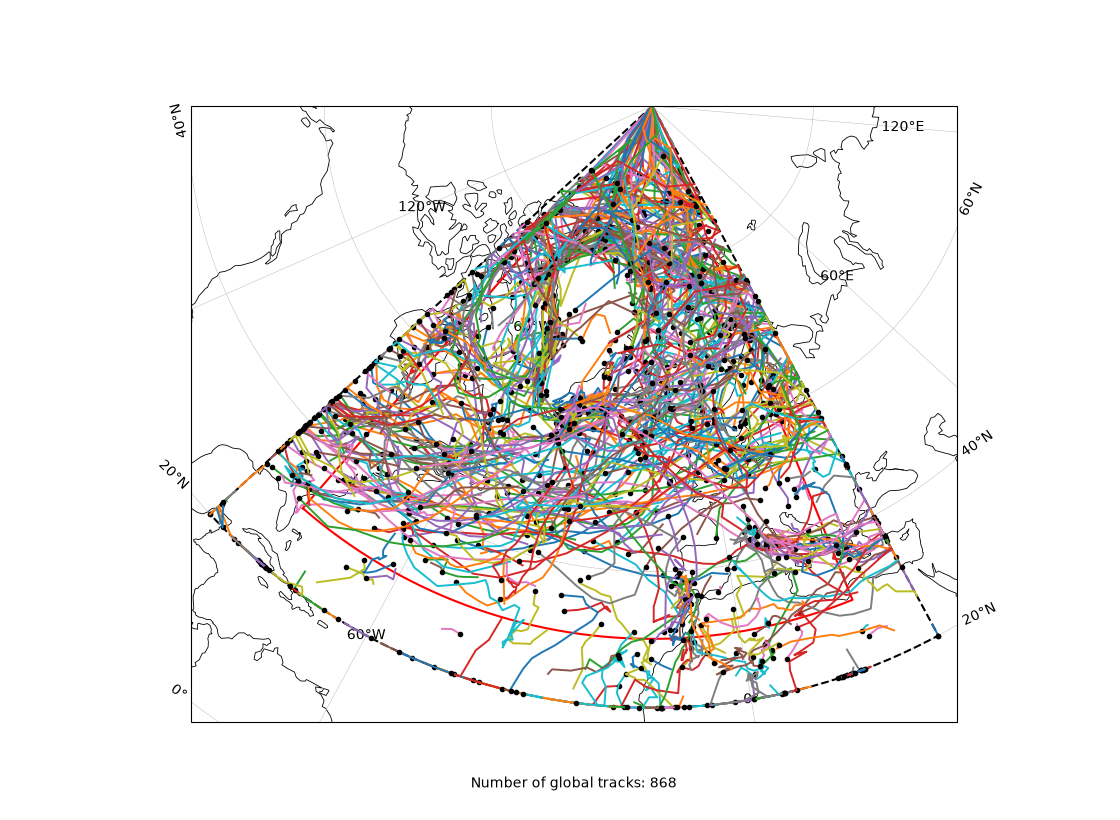

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


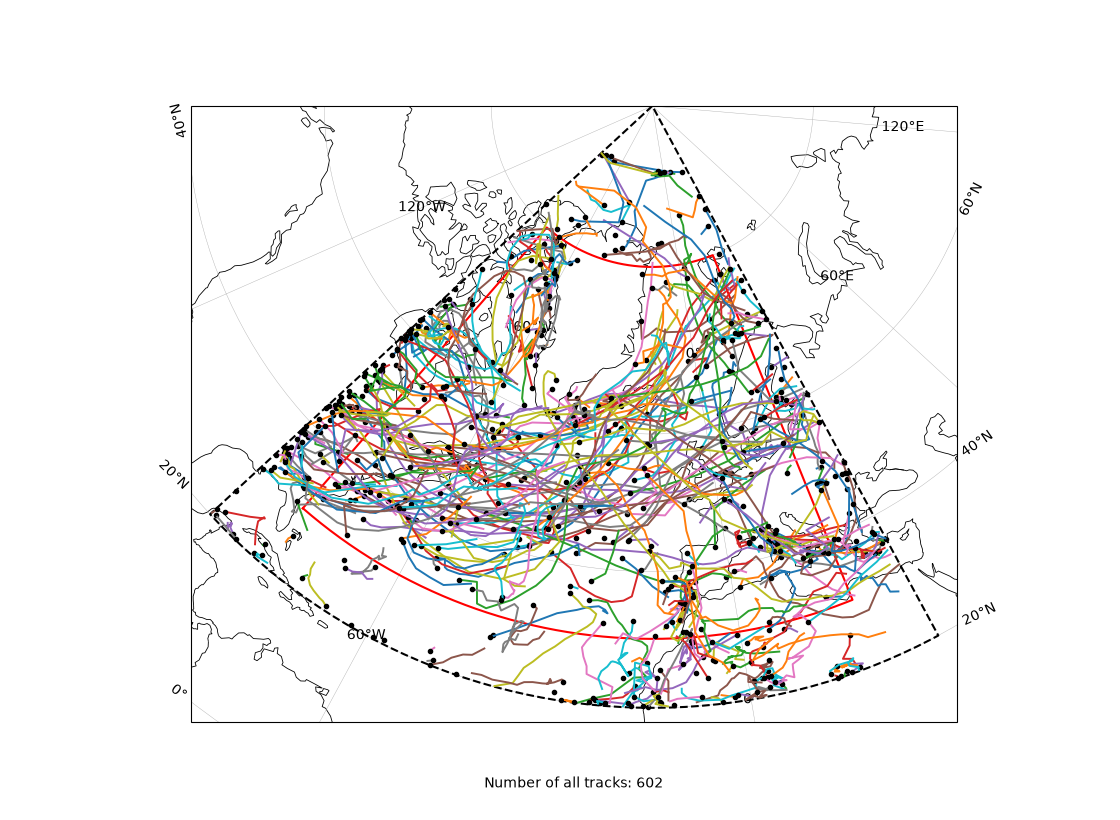

In [198]:
ax = val.plot_regional_tracks(tracks_global, region=REGION, domain=DOMAIN)
ax.set_title("Global Tracks")
ax.text(0.5, -0.1, f"Number of global tracks: {len(tracks_global)}", ha='center', va='center', transform=ax.transAxes) 
plt.show()
ax = val.plot_regional_tracks(tracks_all, region=REGION, domain=DOMAIN)
ax.set_title("All Tracks")
ax.text(0.5, -0.1, f"Number of all tracks: {len(tracks_all)}", ha='center', va='center', transform=ax.transAxes)
plt.show()

In [199]:
tracks_global, summary_global, points_global = pro.postprocess_tracks(tracks_global, **POSTPROCESS_CONFIG)

tracks_all, summary_all, points_all = pro.postprocess_tracks(tracks_all, **POSTPROCESS_CONFIG)

In [200]:
report_validation = pro.filter_report(summary_global)
report_all = pro.filter_report(summary_all)

raw tracks: 868, kept: 203
raw tracks: 602, kept: 114


In [201]:
print("Validation tracks report:")
print(report_validation)
print("\nAll tracks report:")
print(report_all)

Validation tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                        649                             426
region                          97                               3
edge                           176                              13
peak                             0                               0
time                             0                               0

All tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                        476                             294
region                          78                               0
edge                           137                              12
peak                             0                               0
time                             0                               0


In [202]:
comparison, matches_df = val.compare_to_validation(tracks_all, tracks_global, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [203]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,1000,0.978723,23,57.003824,130.551447,23,24,0.000116,0.000154,1,0.000021,0.000023
1,800,28500,0.630137,23,171.442612,773.749272,28,45,0.000061,0.000074,1,0.000003,0.000013
2,5300,23000,0.933333,14,124.910778,222.083225,14,16,0.000032,0.000077,1,0.000026,0.000033
3,7900,18900,0.883721,19,53.442338,137.262249,24,19,0.000120,0.000161,1,0.000024,0.000027
4,9400,1600,0.709677,11,78.590804,187.034982,11,20,0.000061,0.000067,1,0.000005,0.000006
...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,234800,150400,0.714286,10,74.252075,177.774024,10,18,0.000043,0.000061,1,0.000013,0.000013
74,244700,156900,0.625000,10,115.210669,482.523230,21,11,0.000056,0.000072,1,0.000008,0.000010
75,246100,157900,0.952381,10,31.796435,103.602220,11,10,0.000108,0.000125,1,0.000012,0.000012
76,252000,165900,0.941176,8,33.170635,52.617865,9,8,0.000098,0.000126,1,0.000023,0.000025


In [204]:
results_df = pd.Series({
    'Number of global tracks': len(tracks_global),
    'Number of all tracks': len(tracks_all),
    'Number of matched tracks': comparison.tp,
    'Number of missed tracks': comparison.fn,
    'Number of extra tracks': comparison.fp,
    'F1 score': comparison.f1,
    'Precision': comparison.precision,
    'Recall': comparison.recall,
})  

In [205]:
results_df

Number of global tracks     203.000000
Number of all tracks        114.000000
Number of matched tracks     78.000000
Number of missed tracks      36.000000
Number of extra tracks      125.000000
F1 score                      0.492114
Precision                     0.384236
Recall                        0.684211
dtype: float64

In [206]:

# find the verified track ids
verified_candidates = matches_df['candidate_id']
verified_references = matches_df['reference_id']

#filter out the ones we don't keep
global_summary_kept = summary_global[summary_global['keep'] == True]
all_summary_kept = summary_all[summary_all['keep'] == True]

#match the verified tracks to the summary dataframes and the extras
verified_candidate_tracks = global_summary_kept[global_summary_kept['track_id'].isin(verified_candidates)]
extra_tracks = global_summary_kept[~global_summary_kept['track_id'].isin(verified_candidates)]

#find the verified reference tracks and the missed tracks
verified_reference_tracks = all_summary_kept[all_summary_kept['track_id'].isin(verified_references)]
missed_tracks = all_summary_kept[~all_summary_kept['track_id'].isin(verified_references)]


assert len(verified_candidate_tracks) == len(verified_reference_tracks) == comparison.tp
assert len(extra_tracks) == comparison.fp
assert len(missed_tracks) == comparison.fn

Number of extra tracks: 125
Number of extra tracks plotted: 125


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


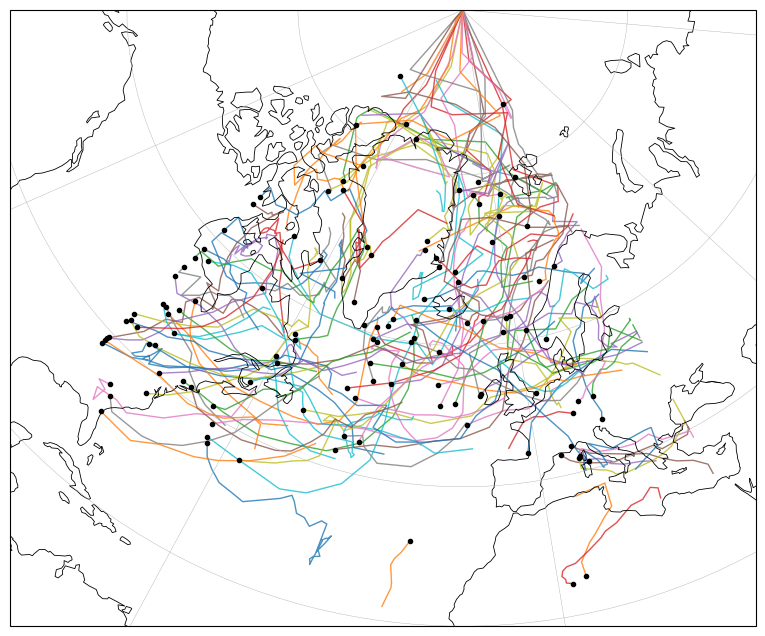

In [207]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of extra tracks: {len(extra_tracks)}")
for tr in tracks_global:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of extra tracks plotted: {i}")

Number of missed tracks: 36
Number of missed tracks plotted: 36
Number of extra tracks: 125


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


Number of extra tracks plotted: 125


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


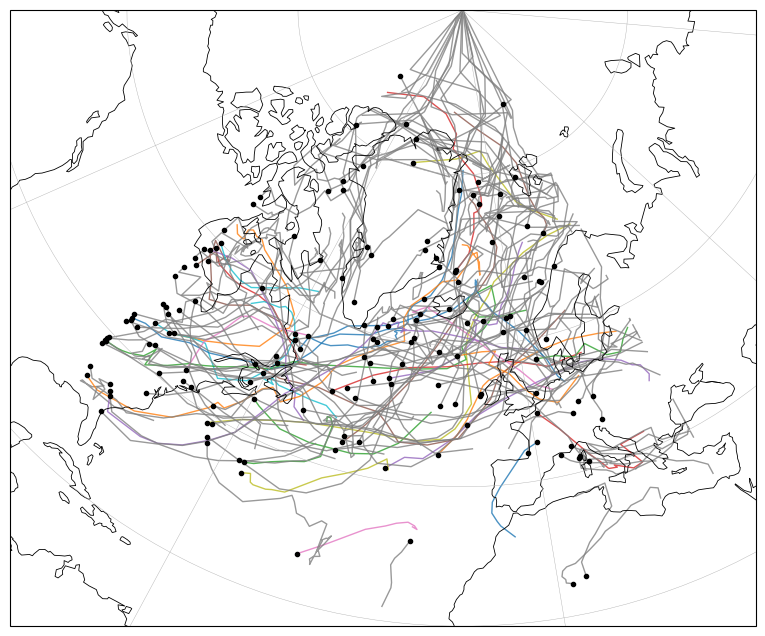

In [208]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of missed tracks: {len(missed_tracks)}")
for tr in tracks_all:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of missed tracks plotted: {i}")
i =0
print(f"Number of extra tracks: {len(extra_tracks)}")
for tr in tracks_global:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1,color="grey", transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of extra tracks plotted: {i}")

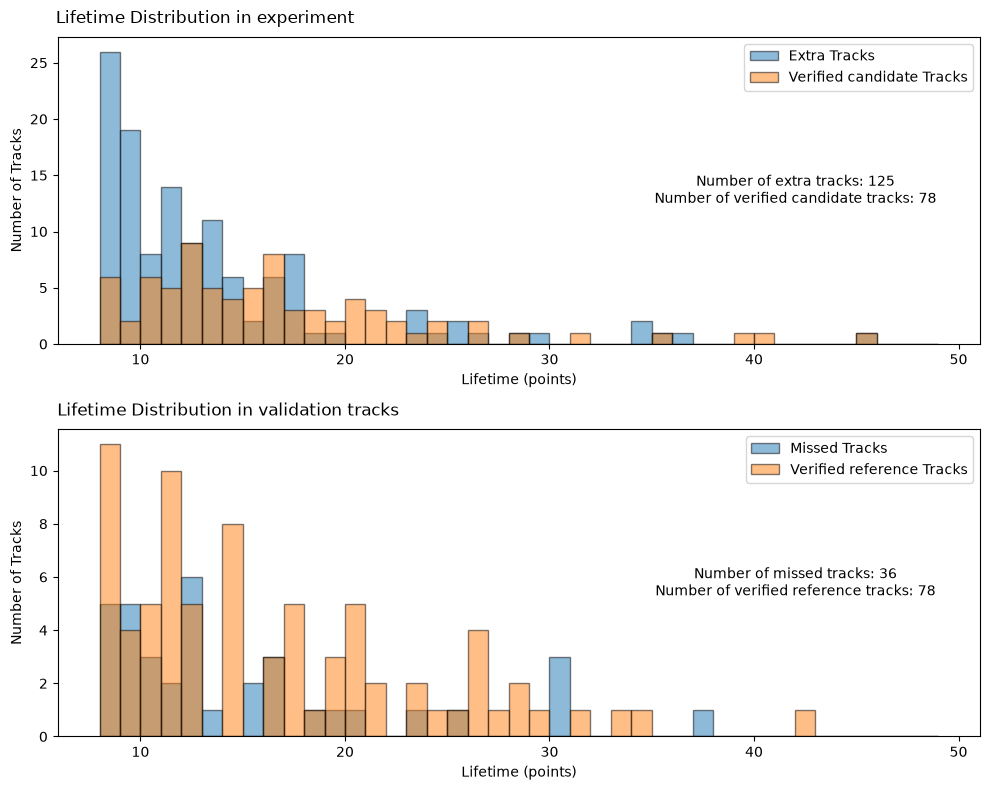

In [209]:
lifetime_cand = verified_candidate_tracks["n_points"].values
lifetime_missed = missed_tracks["n_points"].values
lifetime_ex = extra_tracks["n_points"].values
lifetime_ref = verified_reference_tracks["n_points"].values

counts, edges = np.histogram(lifetime_cand, bins=np.arange(8, 50, 1))
counts_missed, edges_missed = np.histogram(lifetime_missed, bins=np.arange(8, 50, 1))
counts_dis, edges_dis = np.histogram(lifetime_ex, bins=np.arange(8, 50, 1))
counts_val, edges_val = np.histogram(lifetime_ref, bins=np.arange(8, 50, 1))

fig, ax = plt.subplots(2,1,figsize=(10, 8))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified candidate Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified reference Tracks", alpha=0.5)

ax[0].set_xlabel("Lifetime (points)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Lifetime Distribution in experiment", fontsize=12, pad=10, x=0.16)
ax[0].text(0.8, 0.5, f"Number of extra tracks: {len(extra_tracks)}\nNumber of verified candidate tracks: {len(verified_candidate_tracks)}", ha='center', va='center', transform=ax[0].transAxes)
ax[0].legend()

ax[1].set_xlabel("Lifetime (points)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Lifetime Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].text(0.8, 0.5, f"Number of missed tracks: {len(missed_tracks)}\nNumber of verified reference tracks: {len(verified_reference_tracks)}", ha='center', va='center', transform=ax[1].transAxes)
ax[1].legend()

plt.tight_layout()

7.707760209045979
5.650365000000001
6.3081061184124705
5.973986


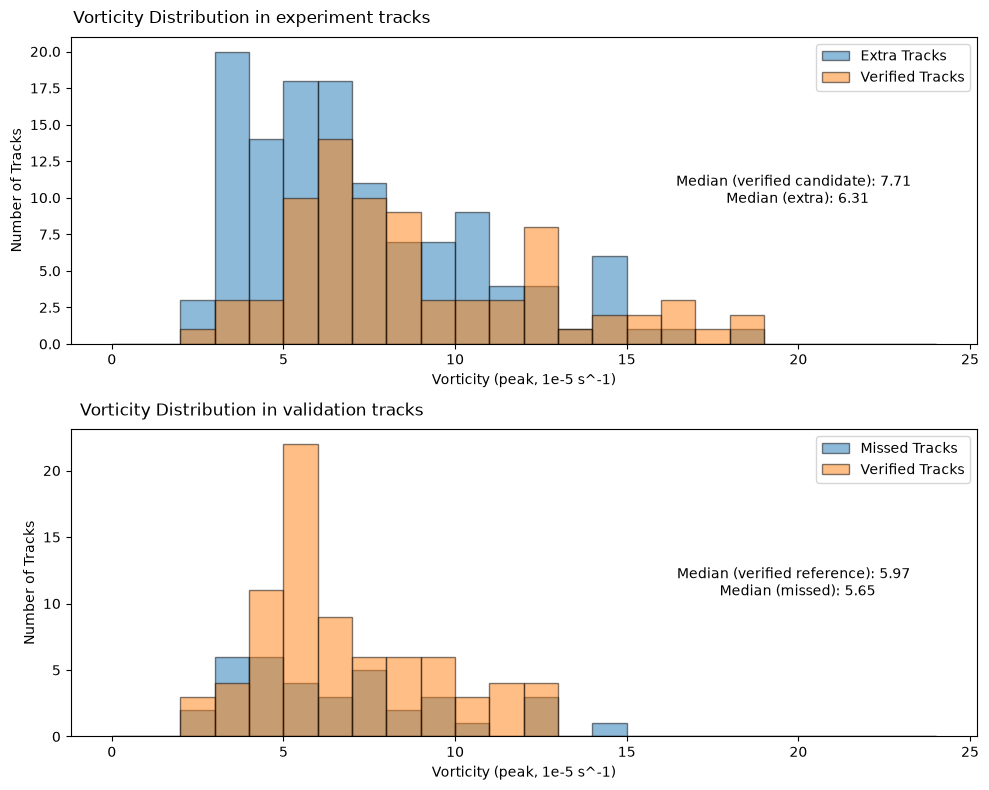

In [210]:
vo_peak_cand = verified_candidate_tracks["vo_peak"].values*1e5
vo_peak_missed = missed_tracks["vo_peak"].values*1e5
vo_peak_ex = extra_tracks["vo_peak"].values*1e5
vo_peak_ref = verified_reference_tracks["vo_peak"].values*1e5

counts, edges = np.histogram(vo_peak_cand, bins=np.arange(0, 25, 1))
counts_missed, edges_missed = np.histogram(vo_peak_missed, bins=np.arange(0, 25, 1))
counts_dis, edges_dis = np.histogram(vo_peak_ex, bins=np.arange(0, 25, 1))
counts_val, edges_val = np.histogram(vo_peak_ref, bins=np.arange(0, 25, 1))
fig, ax = plt.subplots(2,1, figsize=(10, 8))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Vorticity Distribution in experiment tracks", fontsize=12, pad=10, x=0.2)
ax[0].text(0.8, 0.5, f"Median (verified candidate): {np.median(vo_peak_cand):.2f} \n Median (extra): {np.median(vo_peak_ex):.2f}", ha='center', va='center', transform=ax[0].transAxes)
ax[0].legend()

ax[1].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Vorticity Distribution in validation tracks", fontsize=12, pad=10, x=0.2)
ax[1].text(0.8, 0.5, f"Median (verified reference): {np.median(vo_peak_ref):.2f} \n Median (missed): {np.median(vo_peak_missed):.2f}", ha='center', va='center', transform=ax[1].transAxes)
ax[1].legend()

plt.tight_layout()

print(np.median(verified_candidate_tracks["vo_peak"].values*1e5))
print(np.median(missed_tracks["vo_peak"].values*1e5))
print(np.median(extra_tracks["vo_peak"].values*1e5))
print(np.median(verified_reference_tracks["vo_peak"].values*1e5))

In [ ]:
from pystormtracker.preprocessing import SHTFilter

ds = xr.open_dataset("/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5 - pressure levels/19981999_DJF_globe.nc")
ds = ds.sel(valid_time=slice(TIME_RANGE[0], TIME_RANGE[1]))
ds = ds.sel(pressure_level=850)  # select 850 hPa level
ref_pts = helpers.tracks_to_points(tracks_all)
exp_pts = helpers.tracks_to_points(tracks_global)
pp = pd.concat([
    ref_pts[ref_pts.track_id == m.reference_id].merge(
        exp_pts[exp_pts.track_id == m.candidate_id], on="time", suffixes=("_r", "_c"))
    for m in matches_df.itertuples()])
times = pp["time"].drop_duplicates().sample(10, random_state=0).sort_values()
sel = pp[pp["time"].isin(times)]

def local_max(field, t, lat, lon, half=1.5):
    box = field.sel(valid_time=t,
                    latitude=slice(lat - half, lat + half),
                    longitude=slice(lon - half, lon + half))
    if box.size == 0:
        raise ValueError(f"empty box at {t}, lat {lat:.2f}, lon {lon:.2f}")
    return float(box.max())

vo = ds["vo"].sel(valid_time=times.values)      # global, unfiltered, 850 hPa
for taper in [1.0, 0.5, 0.3, 0.1]:
    f = SHTFilter(lmin=5, lmax=42, taper_val=taper).filter(vo)
    f = (f.assign_coords(longitude=((f.longitude + 180) % 360) - 180)
           .sortby("longitude").sortby("latitude"))
    mine = [local_max(f, r.time, r.lat_c, r.lon_c) / r.vo_c for r in sel.itertuples()]
    his  = [local_max(f, r.time, r.lat_r, r.lon_r) / r.vo_r for r in sel.itertuples()]
    print(f"taper {taper}: field/your vo = {np.median(mine):.2f}   field/Priestley vo = {np.median(his):.2f}")

taper 1.0: field/your vo = 1.17   field/Priestley vo = 1.52
taper 0.5: field/your vo = 1.02   field/Priestley vo = 1.30


In [ ]:
f = SHTFilter(lmin=5, lmax=42, taper_val=0.1).filter(vo)
f = (f.assign_coords(longitude=((f.longitude + 180) % 360) - 180)
       .sortby("longitude").sortby("latitude"))
sel = sel.assign(ratio=[local_max(f, r.time, r.lat_r, r.lon_r) / r.vo_r for r in sel.itertuples()])
print(sel["ratio"].describe())
print(sel.groupby(pd.cut(sel["lat_r"], [20, 40, 50, 60, 90]), observed=True)["ratio"].median())

count    39.000000
mean      1.012519
std       0.044885
min       0.852157
25%       1.004894
50%       1.016111
75%       1.029448
max       1.107194
Name: ratio, dtype: float64
lat_r
(20, 40]    1.015459
(40, 50]    1.032126
(50, 60]    1.014185
(60, 90]    1.010164
Name: ratio, dtype: float64
